In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

In [10]:
df = pd.read_csv("creditcard.csv")

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [17]:
X = df.drop("Class", axis=1)
y = df["Class"]

In [18]:
scaler = StandardScaler()

In [19]:
X_scaled = scaler.fit_transform(X)

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [21]:
# dbscan = DBSCAN(eps=0.5, min_samples=5)

# label = dbscan.fit_predict(X_train)

# mask = label != -1

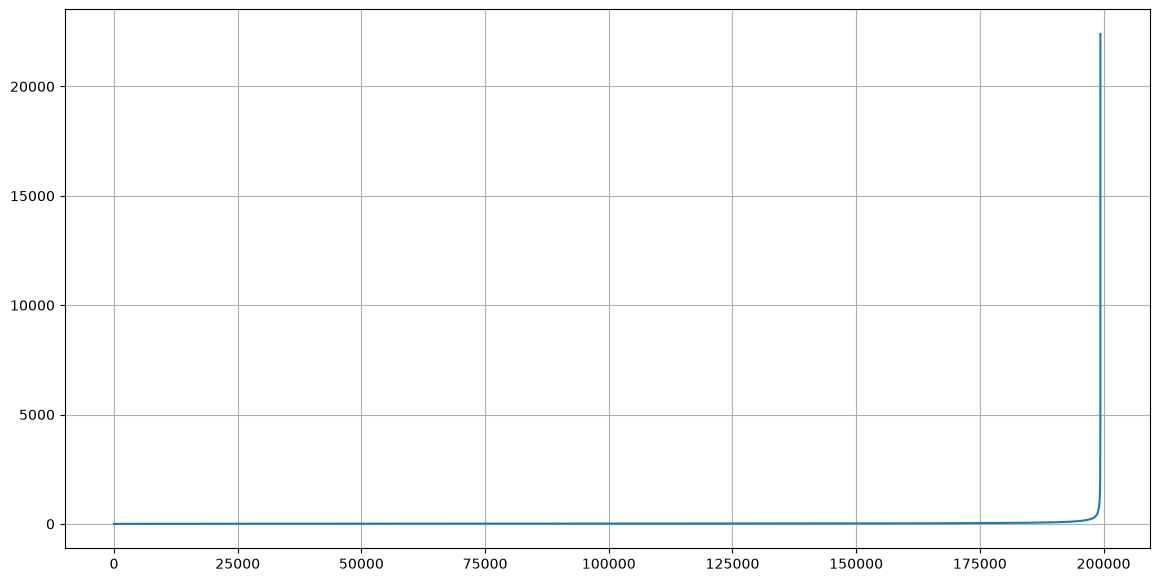

In [22]:
# kneighbor = NearestNeighbors(n_neighbors=5)

# kneighbor_fit = kneighbor.fit(X_train)

# distance, indices = kneighbor_fit.kneighbors(X_train)

# distance = np.sort(distance[:, -1])

# plt.figure(figsize=(14, 7))
# plt.plot(distance)
# plt.grid(True)
# plt.show()

In [24]:
pca = PCA(n_components=2)

x_pca = pca.fit_transform(X_scaled)

In [25]:
x_pca.shape

(284807, 2)

In [27]:
print(sum(pca.explained_variance_ratio_))

0.12139834577465479


In [45]:
full_pca = PCA()

full_X_pca = full_pca.fit_transform(X_scaled)

variances = np.cumsum(
    full_pca.explained_variance_ratio_
)


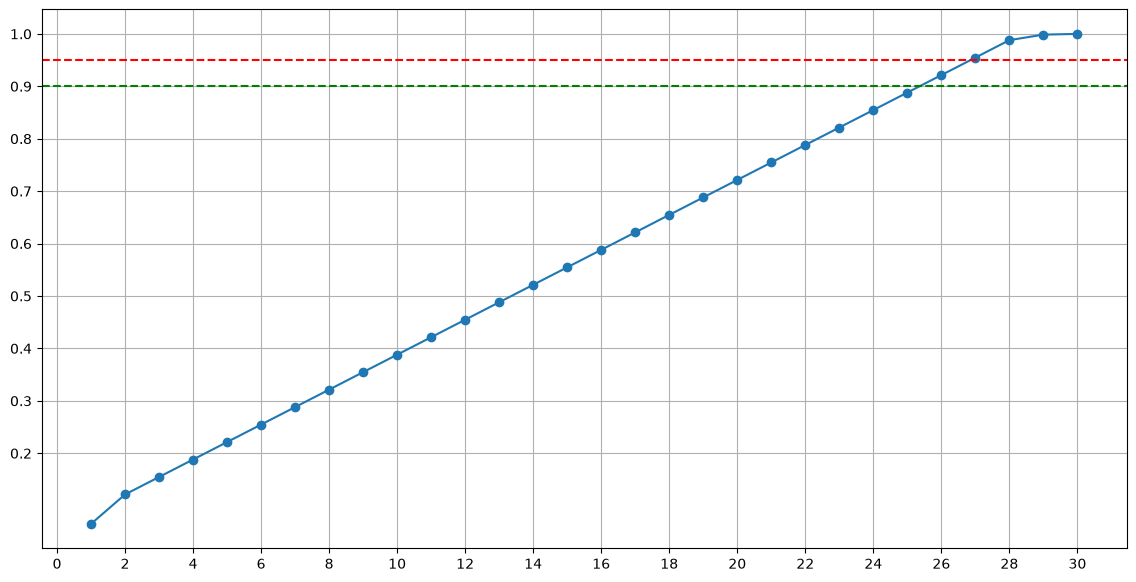

In [46]:
plt.figure(figsize=(14, 7))
plt.plot(
    range(1, 31),
    variances,
    marker="o"
)
plt.grid(True)

plt.axhline(
    y=0.95,
    color="red",
    linestyle="--",
)
plt.axhline(
    y=0.90,
    color="green",
    linestyle="--",
)

plt.xticks(range(0, 31, 2))
plt.yticks(np.arange(0.2, 1.1, 0.1))
plt.show()